# 01 Data overview

**Purpose.** Know what each table holds before modelling: size, time span, coverage, the scenario mix, and the data-quality problems the models must survive.

**Data.** `data/sim/` written by `00_generate_mock_data` (dev scale, seed 7). Every row is simulated.

**Outcome.** A checklist of gaps, duplicates, late readings and offline clamps, with how much of each there is.

In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
from _data import load_tables
from _style import COLORS, label

tables = load_tables()
load, transformers, sin_map, clamps = tables["load"], tables["transformers"], tables["sin_map"], tables["clamps"]

## What is in each table?

In [2]:
describe = {
    "transformers": "one row per transformer: rating, homes, clamp coverage, OSM site, scenario flags",
    "sin_map": "one row per home (sin_hash only): its transformer, clamp, OSM building, EV and solar",
    "clamps": "one row per installed clamp: MQTT client ID, install date, last report",
    "load": "15-minute transformer totals SILIP computes from the clamps, plus true and check-meter kW",
    "households": "15-minute kW per clamped home, for a few detail transformers",
    "readings_raw": "readings as they reached the broker (late and duplicate arrivals included)",
    "weather": "15-minute heat index, rain, weather type and holidays for the region",
    "outages": "one row per outage: cause, start, duration",
    "signals": "last-gasp pings and customer reports per outage",
}
overview = pd.DataFrame(
    {
        "rows": {n: len(t) for n, t in tables.items()},
        "columns": {n: ", ".join(t.columns) for n, t in tables.items()},
        "holds": describe,
        "all is_simulated": {n: bool(t["is_simulated"].all()) for n, t in tables.items()},
    }
)
overview

,rows,columns,holds,all is_simulated
transformers,50,"transformer_id, rated_kva, homes, coverage_pct...","one row per transformer: rating, homes, clamp ...",True
sin_map,2088,"sin_hash, transformer_id, has_clamp, lat, lon,...",one row per home (sin_hash only): its transfor...,True
clamps,1271,"clamp_id, sin_hash, ct_model, installed_at, la...","one row per installed clamp: MQTT client ID, i...",True
load,265938,"transformer_id, ts, transformer_kw, load_pct, ...",15-minute transformer totals SILIP computes fr...,True
households,91916,"sin_hash, transformer_id, ts, power_kw, is_sim...","15-minute kW per clamped home, for a few detai...",True
readings_raw,4424,"sin_hash, transformer_id, ts, power_kw, receiv...",readings as they reached the broker (late and ...,True
weather,5376,"ts, heat_index_c, rain_mm_h, weather, is_holid...","15-minute heat index, rain, weather type and h...",True
outages,189,"outage_id, transformer_id, start_ts, cause, du...","one row per outage: cause, start, duration",True
signals,5483,"outage_id, kind, ts, lat, lon, is_simulated",last-gasp pings and customer reports per outage,True


Takeaway: nine tables, all labeled simulated. `load` is the one the models read.

## What time span and size?

In [3]:
span = load["ts"].agg(["min", "max"])
days = (span["max"] - span["min"]).days + 1
print(f"{transformers.shape[0]} transformers, {sin_map.shape[0]} homes, {days} days "
      f"({span['min']:%Y-%m-%d} to {span['max']:%Y-%m-%d}), {len(load):,} load rows")
transformers[["rated_kva", "homes", "coverage_pct"]].describe().round(2)

50 transformers, 2088 homes, 56 days (2026-04-01 to 2026-05-26), 265,938 load rows


,rated_kva,homes,coverage_pct
count,50.0,50.00,50.00
mean,74.0,41.76,0.60
std,23.8,12.32,0.21
min,25.0,20.00,0.09
25%,50.0,32.25,0.43
50%,75.0,44.00,0.61
75%,100.0,52.00,0.79
max,100.0,60.00,0.97


Takeaway: ratings, home counts and clamp coverage vary widely; coverage runs from about a quarter of homes to nearly all.

## Which scenarios are in the data?

In [4]:
mix = pd.DataFrame(
    {
        "transformers": {
            "loading class: light": (transformers["loading_class"] == "light").sum(),
            "loading class: normal": (transformers["loading_class"] == "normal").sum(),
            "loading class: tight": (transformers["loading_class"] == "tight").sum(),
            "loading class: over": (transformers["loading_class"] == "over").sum(),
            "EV neighbourhood": transformers["ev_site"].sum(),
            "has solar homes": (transformers["solar_homes"] > 0).sum(),
            "unmetered jumper load": transformers["has_jumper"].sum(),
            "check meter": transformers["has_check_meter"].sum(),
            "load lead-up before failure": transformers["lead_up"].sum(),
        }
    }
)
mix["share"] = (mix["transformers"] / len(transformers)).round(2)
mix

,transformers,share
loading class: light,15,0.30
loading class: normal,22,0.44
loading class: tight,6,0.12
loading class: over,7,0.14
EV neighbourhood,12,0.24
has solar homes,36,0.72
unmetered jumper load,8,0.16
check meter,14,0.28
load lead-up before failure,7,0.14


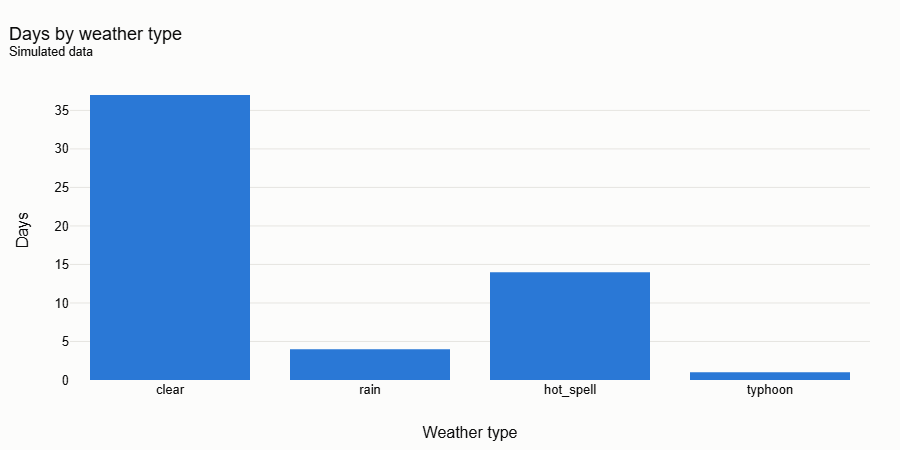

In [5]:
weather_days = tables["weather"].groupby(tables["weather"]["ts"].dt.date).agg(
    weather=("weather", "first"), holiday=("is_holiday", "first")
)
fig = px.histogram(weather_days, x="weather", color_discrete_sequence=COLORS[:1])
label(fig, "Days by weather type", "Weather type", "Days").show()

Takeaway: mostly clear hot-season days, with hot spells, a few rain days and one typhoon.

## How complete is the load table?
Each transformer should have 96 rows a day. Rows are missing when no clamp on the transformer reported, which happens during outages.

In [6]:
expected = days * 96
per_tx = load.groupby("transformer_id").size()
gaps = pd.DataFrame({"missing intervals": expected - per_tx, "missing share": 1 - per_tx / expected})
gaps.describe().round(3)

,missing intervals,missing share
count,50.00,50.000
mean,57.24,0.011
std,36.02,0.007
min,0.00,0.000
25%,29.25,0.005
50%,50.50,0.009
75%,77.75,0.014
max,159.00,0.030


In [7]:
outage_minutes = tables["outages"].groupby("transformer_id")["duration_min"].sum()
check = gaps.join(outage_minutes.rename("outage_minutes")).fillna(0)
print(f"correlation between missing intervals and outage minutes: {check.corr().iloc[0, 2]:.2f}")

correlation between missing intervals and outage minutes: 1.00


Takeaway: about 1% of intervals are missing (at most about 3% on one transformer), and they line up exactly with outages: when the power goes, the clamps go quiet too.

## How many homes report in each interval?

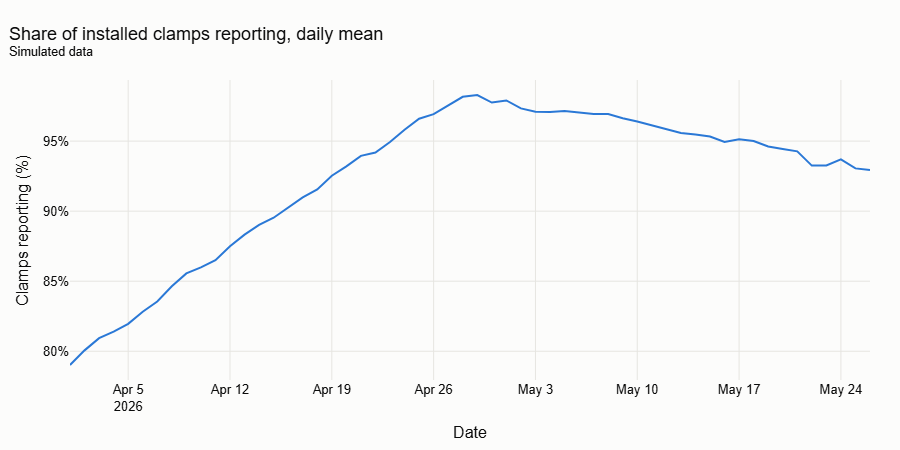

In [8]:
clamped = sin_map.groupby("transformer_id")["has_clamp"].sum()
reporting = load.merge(clamped.rename("clamped"), on="transformer_id")
reporting["reporting_share"] = reporting["homes_reporting"] / reporting["clamped"]
daily = reporting.groupby(reporting["ts"].dt.date)["reporting_share"].mean().reset_index()
fig = px.line(daily, x="ts", y="reporting_share", color_discrete_sequence=COLORS[:1])
fig.update_yaxes(tickformat=".0%")
label(fig, "Share of installed clamps reporting, daily mean", "Date", "Clamps reporting (%)").show()

Takeaway: the share climbs through April as late installs come online, then drifts down as clamps die or lose Wi-Fi. Coverage is not a constant.

## Duplicates, late readings and offline clamps

In [9]:
raw = tables["readings_raw"]
end = load["ts"].max()
quality = pd.Series(
    {
        "duplicate readings in raw sample": int(raw.duplicated(["sin_hash", "ts"]).sum()),
        "late readings in raw sample (> 15 min after window)": int(
            (raw["received_at"] > raw["ts"] + pd.Timedelta(minutes=30)).sum()
        ),
        "raw sample rows": len(raw),
        "duplicate readings dropped (all transformers)": int(load["duplicate_readings"].sum()),
        "late readings accepted (all transformers)": int(load["late_readings"].sum()),
        "clamps silent for more than a day at the end": int(
            (clamps["last_seen_at"] < end - pd.Timedelta(days=1)).sum()
        ),
        "clamps installed": len(clamps),
        "intervals with negative transformer kW (solar)": int((load["transformer_kw"] < 0).sum()),
    }
)
quality.to_frame("count")

,count
duplicate readings in raw sample,22
late readings in raw sample (> 15 min after window),76
raw sample rows,4424
duplicate readings dropped (all transformers),31523
late readings accepted (all transformers),125565
clamps silent for more than a day at the end,69
clamps installed,1271
intervals with negative transformer kW (solar),766


Takeaway: duplicates and late arrivals are rare but real, so aggregation must deduplicate by `(sin_hash, ts)` and accept late rows. A few clamps die for good and need a visit.

## How far is SILIP's total from the truth?
SILIP scales the clamped homes up to all homes. Only a check meter shows the true total, including unmetered jumper load.

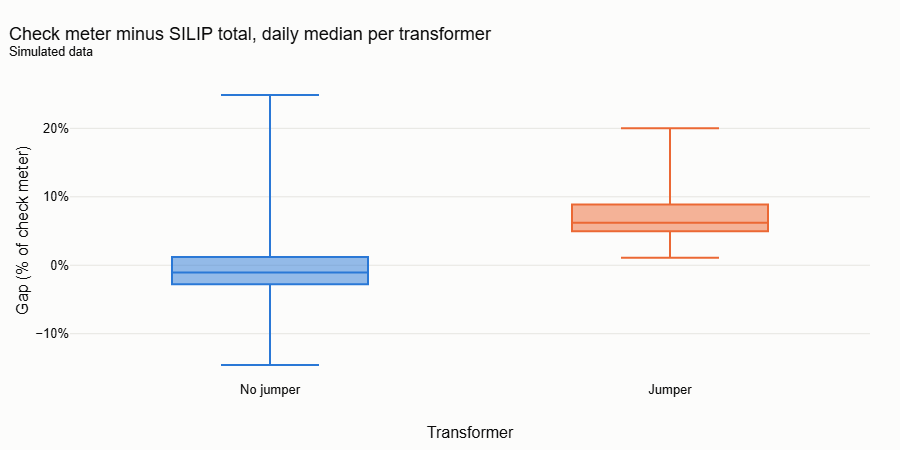

In [10]:
with_meter = load.dropna(subset=["check_meter_kw"]).merge(
    transformers[["transformer_id", "has_jumper"]], on="transformer_id"
)
with_meter["gap_share"] = (with_meter["check_meter_kw"] - with_meter["transformer_kw"]) / with_meter["check_meter_kw"]
daily_gap = with_meter.groupby(["transformer_id", with_meter["ts"].dt.date, "has_jumper"])["gap_share"].median().reset_index()
fig = px.box(daily_gap, x="has_jumper", y="gap_share", points=False, color="has_jumper", color_discrete_sequence=COLORS)
fig.update_layout(showlegend=False)
fig.update_yaxes(tickformat=".0%")
fig.update_xaxes(tickvals=[False, True], ticktext=["No jumper", "Jumper"])
label(fig, "Check meter minus SILIP total, daily median per transformer", "Transformer", "Gap (% of check meter)").show()

Takeaway: without jumpers the gap centres near zero; with jumpers it sits a few percent above zero, mostly under the 15% flag from the silip-domain rule. Small jumpers are hard to catch, and only transformers with a check meter can show them at all.

**Outcome.** The load table is complete enough to model, gaps follow outages, and the jumper signal exists only where a check meter does. Next: `02_eda`.